## NN and DL-HW3-Q1


### 1-1.Data set


the code inside the file HW3-Q1-dataprep:


#### 1-1-1. Research and explanations


In [1]:
from google.colab import drive

# Mount Google Drive to /content/drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [2]:
import os
import glob
import zipfile
import numpy as np
import nibabel as nib
import warnings
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# 1. Automatic File Finder
def find_zip_in_drive(filename='IBSR_nifti_stripped.zip'):
    print(f"Searching for {filename} in Google Drive...")
    # Search in MyDrive
    search_pattern = os.path.join('/content/drive/MyDrive', '**', filename)
    found_files = glob.glob(search_pattern, recursive=True)

    if len(found_files) > 0:
        print(f"Found file at: {found_files[0]}")
        return found_files[0]
    else:
        print("Error: File not found! Make sure you added a shortcut of the zip file to 'My Drive'.")
        return None

# 2. Unzip Dataset
def unzip_dataset(zip_path, extract_to):
    if not os.path.exists(zip_path):
        print(f"Error: Zip file not found at {zip_path}")
        return False

    # Check if already extracted
    if os.path.exists(extract_to) and len(os.listdir(extract_to)) > 0:
        print(f"Directory {extract_to} already exists. Skipping extraction.")
        return True

    print(f"Extracting {zip_path} to {extract_to}...")
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_to)
        print("Extraction complete.")
        return True
    except Exception as e:
        print(f"Error during extraction: {e}")
        return False

# 3. Helper functions
def get_slice_data(volume_data, seg_data, axis, slice_idx):
    if axis == 0:
        vol_slice = volume_data[slice_idx, :, :]
        seg_slice = seg_data[slice_idx, :, :]
    elif axis == 1:
        vol_slice = volume_data[:, slice_idx, :]
        seg_slice = seg_data[:, slice_idx, :]
    else:
        vol_slice = volume_data[:, :, slice_idx]
        seg_slice = seg_data[:, :, slice_idx]

    vol_slice = np.squeeze(vol_slice)
    seg_slice = np.squeeze(seg_slice)

    # Rotate 90 degrees clockwise
    vol_slice_rotated = np.rot90(vol_slice, k=1)
    seg_slice_rotated = np.rot90(seg_slice, k=1)

    return vol_slice_rotated, seg_slice_rotated

def pad_slice(vol_slice, seg_slice, target_dims=(256, 256)):
    h, w = vol_slice.shape
    th, tw = target_dims

    pad_h_top = (th - h) // 2
    pad_h_bottom = th - h - pad_h_top
    pad_w_left = (tw - w) // 2
    pad_w_right = tw - w - pad_w_left

    padding = ((max(0, pad_h_top), max(0, pad_h_bottom)),
               (max(0, pad_w_left), max(0, pad_w_right)))

    vol_padded = np.pad(vol_slice, padding, mode='constant', constant_values=0)
    seg_padded = np.pad(seg_slice, padding, mode='constant', constant_values=0)

    vol_padded = vol_padded[:th, :tw]
    seg_padded = seg_padded[:th, :tw]

    return vol_padded, seg_padded

# 4. Dataset Class
class IBSRPatchDataset(Dataset):
    def __init__(self, volume_files, segmentation_files):
        self.patches = []
        self.masks = []
        self.patch_size = 128

        print(f"Processing {len(volume_files)} subjects...")
        for vol_path, seg_path in zip(volume_files, segmentation_files):
            try:
                # Load data
                vol_img = nib.load(vol_path).get_fdata().astype(np.float32)
                seg_img = nib.load(seg_path).get_fdata().astype(np.int64)

                # Normalize to [0, 1]
                max_val = vol_img.max()
                if max_val > 0:
                    vol_img = vol_img / max_val

                for axis in range(3):
                    # Take slices
                    indices = range(10, vol_img.shape[axis], 3)[:48]
                    for idx in indices:
                        vol_slice, seg_slice = get_slice_data(vol_img, seg_img, axis, idx)
                        vol_padded, seg_padded = pad_slice(vol_slice, seg_slice)

                        # Extract patches
                        for x in [0, 128]:
                            for y in [0, 128]:
                                img_patch = vol_padded[x:x+128, y:y+128]
                                mask_patch = seg_padded[x:x+128, y:y+128]

                                # ONLY SAVE PATCH IF IT HAS LABELS
                                # Check if the mask contains any label other than 0 (Background)
                                if np.any(mask_patch > 0):
                                    self.patches.append(img_patch)
                                    self.masks.append(mask_patch)

            except Exception as e:
                print(f"Skipping {vol_path}: {e}")

        print(f"Dataset loaded. Total patches containing tissue: {len(self.patches)}")

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        vol_patch = self.patches[idx]
        seg_patch = self.masks[idx]

        vol_tensor = torch.tensor(vol_patch, dtype=torch.float32).unsqueeze(0)
        mask_tensor = torch.tensor(seg_patch, dtype=torch.long)

        return vol_tensor, mask_tensor

# 5. Main Execution Flow

# Attempt to find the zip file automatically
drive_zip_path = find_zip_in_drive()

if drive_zip_path:
    # Local directory to extract files
    local_extract_path = '/content/dataset'

    if unzip_dataset(drive_zip_path, local_extract_path):

        # Search recursively for .nii.gz files inside the extracted folder
        # This handles nested folders like IBSR_nifti_stripped/IBSR_01/...
        search_path = os.path.join(local_extract_path, '**')

        vol_files = sorted(glob.glob(os.path.join(search_path, '*_ana_strip.nii.gz'), recursive=True))
        seg_files = sorted(glob.glob(os.path.join(search_path, '*_segTRI_fill_ana.nii.gz'), recursive=True))

        if len(vol_files) == 0:
            print("Error: No .nii.gz files found after extraction. Please check the zip content.")
        else:
            print(f"Found {len(vol_files)} subjects.")

            # Split data
            train_vol, val_vol, train_seg, val_seg = train_test_split(
                vol_files, seg_files, test_size=0.2, random_state=42
            )

            print(f"Training subjects: {len(train_vol)}")
            print(f"Validation subjects: {len(val_vol)}")

            # Create Datasets
            train_dataset = IBSRPatchDataset(train_vol, train_seg)
            val_dataset = IBSRPatchDataset(val_vol, val_seg)

            # Create DataLoaders
            train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
            val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False)

            print("DataLoaders created successfully!")
    else:
        print("Failed to unzip.")
else:
    print("Stopping execution because zip file was not found.")


Searching for IBSR_nifti_stripped.zip in Google Drive...
Found file at: /content/drive/MyDrive/Deep_Learning_Neural_Networks/NNDL_Assignment3/IBSR dataset Skull stripped/IBSR_nifti_stripped.zip
Directory /content/dataset already exists. Skipping extraction.
Found 18 subjects.
Training subjects: 14
Validation subjects: 4
Processing 14 subjects...
Dataset loaded. Total patches containing tissue: 5371
Processing 4 subjects...
Dataset loaded. Total patches containing tissue: 1528
DataLoaders created successfully!


#### 1-1-2. Parameters


#### 1-1-3. Visualizing the data


Visualizing 3 Random Subjects (Full Slices):


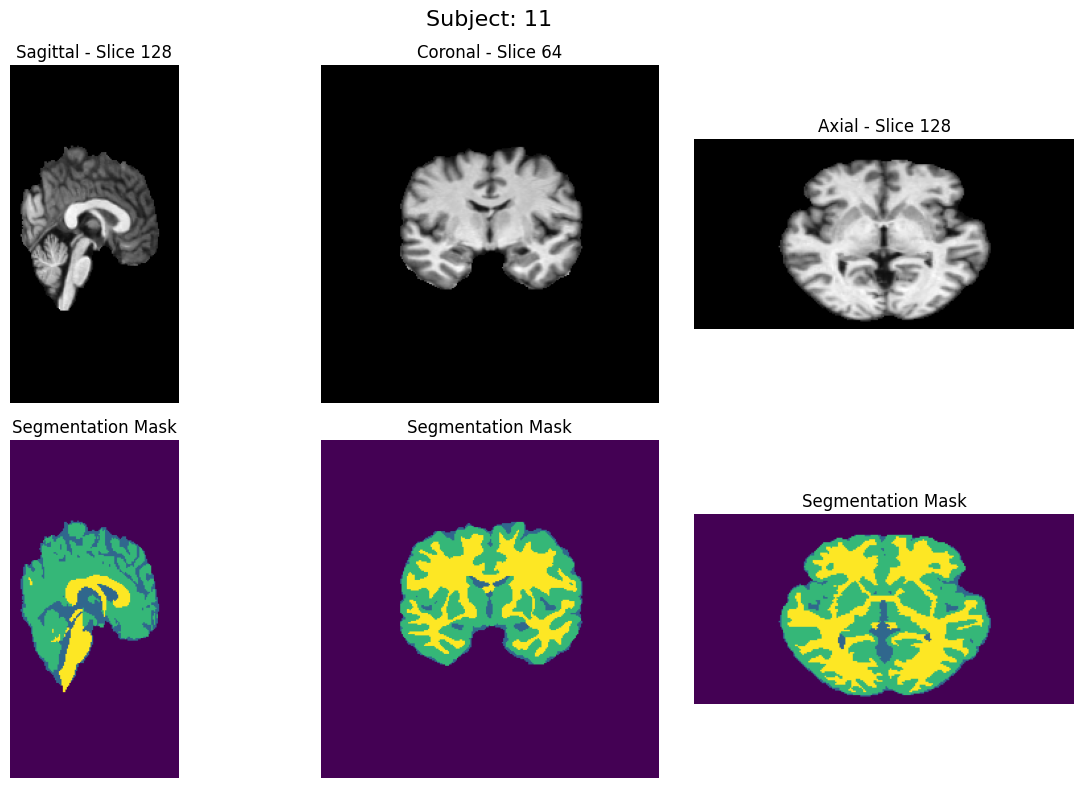

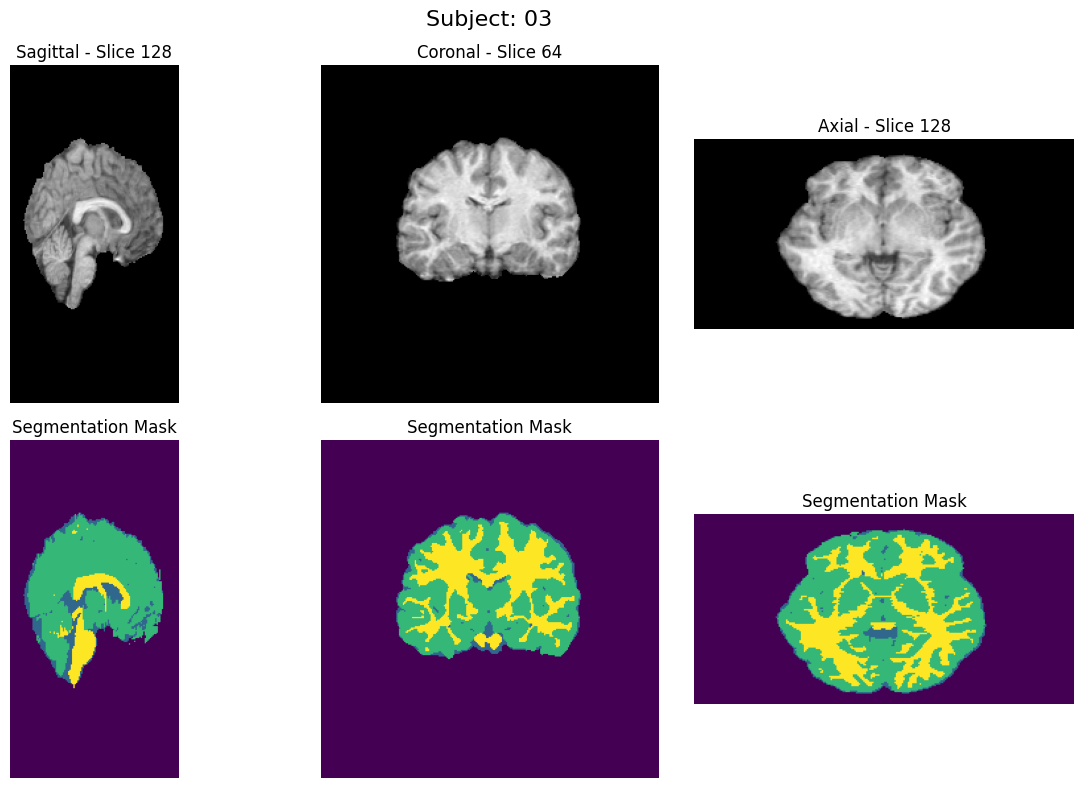

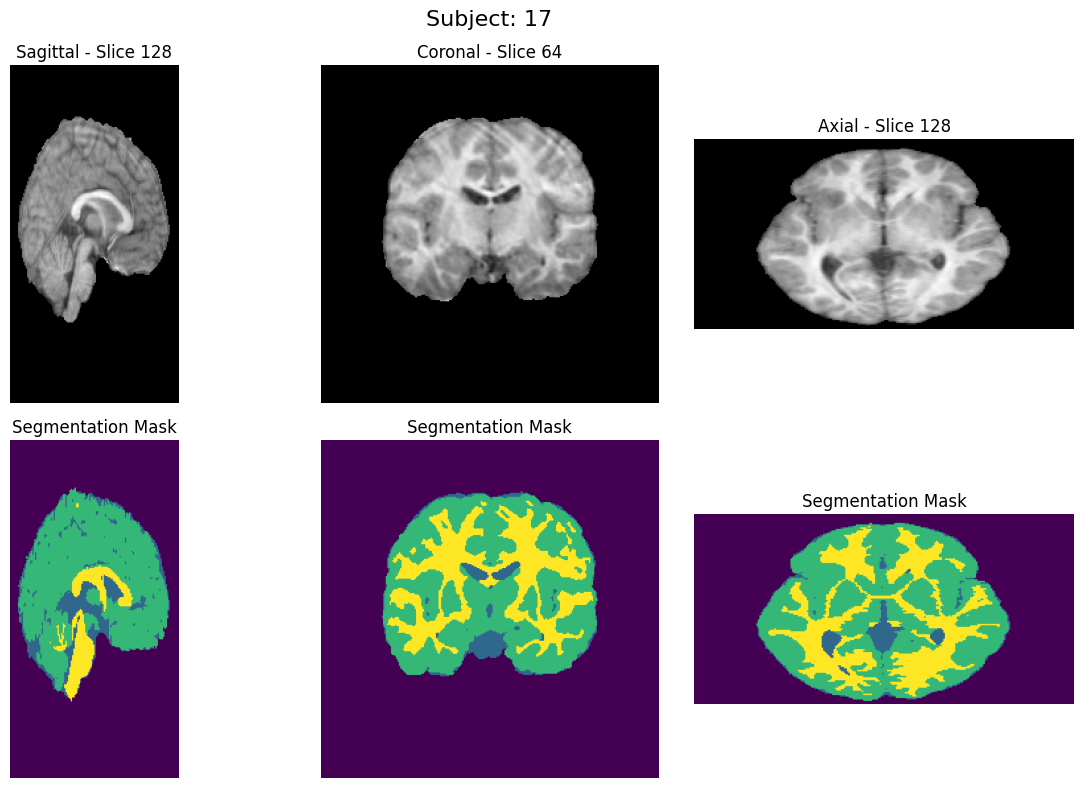


Visualizing 3 Random Patches (Network Inputs):


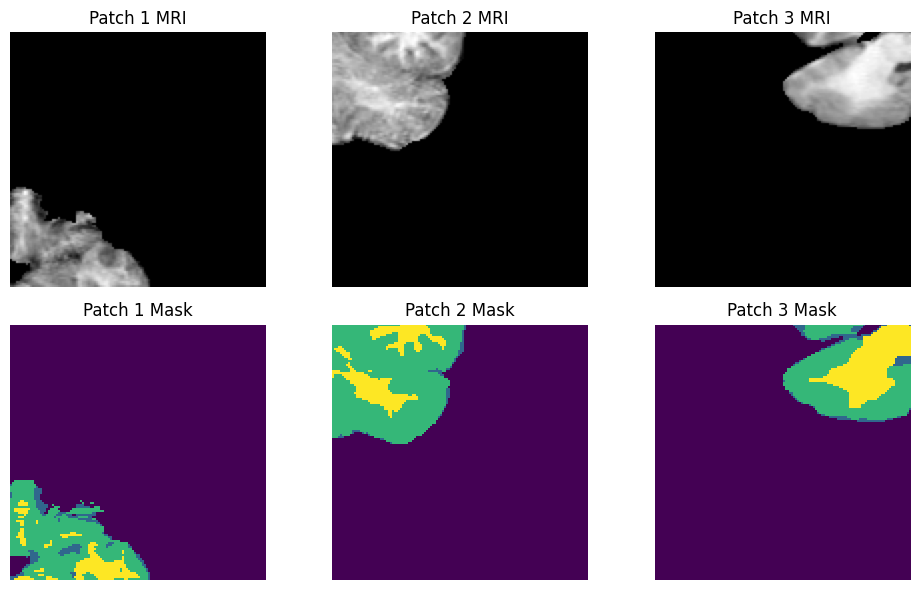

In [3]:
import matplotlib.pyplot as plt
import random
import nibabel as nib
import numpy as np
import os

# Function to show full slices from the original volumes
def show_subject_slices(vol_path, seg_path, subject_id):
    # Load the NIfTI files
    vol_img = nib.load(vol_path).get_fdata()
    seg_img = nib.load(seg_path).get_fdata()

    # Handle potential 4D data
    if vol_img.ndim == 4:
        vol_img = vol_img.squeeze()
    if seg_img.ndim == 4:
        seg_img = seg_img.squeeze()

    # Get volume dimensions
    x_dim, y_dim, z_dim = vol_img.shape

    # Select middle slices for each axis
    slice_indices = [x_dim // 2, y_dim // 2, z_dim // 2]
    axis_names = ['Sagittal', 'Coronal', 'Axial']

    # Create figure
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    plt.suptitle(f"Subject: {subject_id}", fontsize=16)

    for i in range(3):
        # Extract slices based on axis
        if i == 0:
            vol_slice = vol_img[slice_indices[i], :, :]
            seg_slice = seg_img[slice_indices[i], :, :]
        elif i == 1:
            vol_slice = vol_img[:, slice_indices[i], :]
            seg_slice = seg_img[:, slice_indices[i], :]
        else:
            vol_slice = vol_img[:, :, slice_indices[i]]
            seg_slice = seg_img[:, :, slice_indices[i]]

        # Rotate for correct orientation
        vol_slice = np.rot90(vol_slice, k=1)
        seg_slice = np.rot90(seg_slice, k=1)

        # Show MRI
        axes[0, i].imshow(vol_slice, cmap='gray')
        axes[0, i].set_title(f"{axis_names[i]} - Slice {slice_indices[i]}")
        axes[0, i].axis('off')

        # Show Mask
        axes[1, i].imshow(seg_slice, cmap='viridis')
        axes[1, i].set_title("Segmentation Mask")
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

# Visualize 3 random subjects
if 'train_vol' in globals():
    random_indices = random.sample(range(len(train_vol)), 3)
    print("Visualizing 3 Random Subjects (Full Slices):")
    for idx in random_indices:
        subj_name = os.path.basename(train_vol[idx]).split('_')[1]
        show_subject_slices(train_vol[idx], train_seg[idx], subj_name)

# Function to show patches from the loader
def show_patches(dataloader, num_samples=3):
    print(f"\nVisualizing {num_samples} Random Patches (Network Inputs):")

    fig, axes = plt.subplots(2, num_samples, figsize=(10, 6))

    # Create an iterator to fetch distinct batches
    data_iter = iter(dataloader)

    for i in range(num_samples):
        try:
            # Fetch the next batch (contains 1 image because batch_size=1)
            images, masks = next(data_iter)

            # Squeeze to remove batch channel
            img_np = images[0].squeeze().numpy()
            mask_np = masks[0].numpy()

            # Show Patch MRI
            axes[0, i].imshow(img_np, cmap='gray')
            axes[0, i].set_title(f"Patch {i+1} MRI")
            axes[0, i].axis('off')

            # Show Patch Mask
            axes[1, i].imshow(mask_np, cmap='viridis')
            axes[1, i].set_title(f"Patch {i+1} Mask")
            axes[1, i].axis('off')
        except StopIteration:
            print("Not enough samples in dataloader.")
            break

    plt.tight_layout()
    plt.show()

# Visualize patches
if 'train_loader' in globals():
    show_patches(train_loader)


In [4]:
# Data Diagnostic Code
# Run this cell BEFORE training to check input statistics

print("--- Data Diagnostic ---")

# Fetch one batch from the training loader
try:
    sample_img, sample_mask = next(iter(train_loader))

    print(f"Input Shape: {sample_img.shape}")
    print(f"Data Type: {sample_img.dtype}")

    # Check Statistics
    min_val = sample_img.min().item()
    max_val = sample_img.max().item()
    mean_val = sample_img.mean().item()

    print(f"Min Value: {min_val:.4f}")
    print(f"Max Value: {max_val:.4f}")
    print(f"Mean Value: {mean_val:.4f}")
    print("-" * 20)
    print(f"Mask Shape: {sample_mask.shape}")
    print(f"Unique Labels in Mask: {torch.unique(sample_mask).tolist()}")

    # Check for NaNs
    if torch.isnan(sample_img).any():
        print("ALERT: Input data contains NaNs!")
    else:
        print("Input data is clean (No NaNs).")

    # Check for large values
    if max_val > 10.0:
        print("\nCRITICAL WARNING: Large input values detected!")
        print(f"Max value is {max_val:.2f}. Neural networks typically need inputs between 0 and 1.")
        print("This explains the NaN loss. We MUST normalize the data.")
    else:
        print("\nData range looks okay.")

except NameError:
    print("Error: 'train_loader' is not defined. Please run the Data Loading cell first.")
except StopIteration:
    print("Error: DataLoader is empty.")


--- Data Diagnostic ---
Input Shape: torch.Size([1, 1, 128, 128])
Data Type: torch.float32
Min Value: 0.0000
Max Value: 0.8284
Mean Value: 0.0936
--------------------
Mask Shape: torch.Size([1, 128, 128])
Unique Labels in Mask: [0, 1, 2, 3]
Input data is clean (No NaNs).

Data range looks okay.


### 1-2.Model implimentation


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Basic Convolutional Block consisting of Conv2d, BatchNorm, and ReLU
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, padding=0):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, padding=padding),
            nn.InstanceNorm2d(out_ch),#nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

# M-Net Architecture based on the provided article
class MNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=4):
        super(MNet, self).__init__()

        # Encoder Path (Left Leg)
        # According to Table 3 in the paper, the encoder uses 1x1 kernels

        # Level 1
        self.enc1_1 = ConvBlock(in_channels, 64, kernel_size=1, padding=0)
        self.enc1_2 = ConvBlock(64, 64, kernel_size=1, padding=0)
        self.pool1 = nn.MaxPool2d(2, stride=2)

        # Level 2
        self.enc2_1 = ConvBlock(64, 128, kernel_size=1, padding=0)
        self.enc2_2 = ConvBlock(128, 128, kernel_size=1, padding=0)
        self.pool2 = nn.MaxPool2d(2, stride=2)

        # Level 3
        self.enc3_1 = ConvBlock(128, 256, kernel_size=1, padding=0)
        self.enc3_2 = ConvBlock(256, 256, kernel_size=1, padding=0)
        self.pool3 = nn.MaxPool2d(2, stride=2)

        # Level 4 (Bridge / Bottleneck)
        self.bottleneck1 = ConvBlock(256, 512, kernel_size=1, padding=0)
        self.bottleneck2 = ConvBlock(512, 512, kernel_size=1, padding=0)

        # Decoder Path (Right Leg)
        # According to Table 3 in the paper, the decoder uses 3x3 kernels

        # Up-Level 3
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        # Input channels are 512 because we concatenate the skip connection
        self.dec3_1 = ConvBlock(512, 256, kernel_size=3, padding=1)
        self.dec3_2 = ConvBlock(256, 256, kernel_size=3, padding=1)

        # Up-Level 2
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2_1 = ConvBlock(256, 128, kernel_size=3, padding=1)
        self.dec2_2 = ConvBlock(128, 128, kernel_size=3, padding=1)

        # Up-Level 1
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1_1 = ConvBlock(128, 64, kernel_size=3, padding=1)
        self.dec1_2 = ConvBlock(64, 64, kernel_size=3, padding=1)

        # Final Output Layer (1x1 convolution to map to number of classes)
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

        # Apply the requested LeCun initialization
        self._initialize_weights()

    def forward(self, x):
        # Encoder Forward Pass
        # Block 1
        x1 = self.enc1_1(x)
        x1 = self.enc1_2(x1)
        p1 = self.pool1(x1)

        # Block 2
        x2 = self.enc2_1(p1)
        x2 = self.enc2_2(x2)
        p2 = self.pool2(x2)

        # Block 3
        x3 = self.enc3_1(p2)
        x3 = self.enc3_2(x3)
        p3 = self.pool3(x3)

        # Bottleneck
        b = self.bottleneck1(p3)
        b = self.bottleneck2(b)

        # Decoder Forward Pass
        # Block 3
        d3 = self.up3(b)
        # Concatenate with skip connection from Encoder Level 3
        d3 = torch.cat((x3, d3), dim=1)
        d3 = self.dec3_1(d3)
        d3 = self.dec3_2(d3)

        # Block 2
        d2 = self.up2(d3)
        d2 = torch.cat((x2, d2), dim=1)
        d2 = self.dec2_1(d2)
        d2 = self.dec2_2(d2)

        # Block 1
        d1 = self.up1(d2)
        d1 = torch.cat((x1, d1), dim=1)
        d1 = self.dec1_1(d1)
        d1 = self.dec1_2(d1)

        # Final prediction
        out = self.final_conv(d1)
        return out

    # Weight Initialization Method (LeCun Normal)
    # This fulfills the requirement in section 1-3-2 of the assignment
    def _initialize_weights(self):
        print("Applying LeCun Initialization...")
        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.ConvTranspose2d):
                # Calculate fan_in using PyTorch internal utility
                fan_in, _ = nn.init._calculate_fan_in_and_fan_out(m.weight)

                # Calculate standard deviation for LeCun Normal: std = sqrt(1 / fan_in)
                std = (1.0 / fan_in) ** 0.5

                # Apply normal distribution with calculated std
                nn.init.normal_(m.weight, mean=0.0, std=std)

                # Initialize bias to zero if it exists
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

# Model Sanity Check
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MNet(in_channels=1, num_classes=4).to(device)

# Re-initialize the model with InstanceNorm
model = MNet(in_channels=1, num_classes=4).to(device)
print(" Model re-initialized with Instance Normalization.")

# Count trainable parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {trainable_params}")


Applying LeCun Initialization...
Applying LeCun Initialization...
 Model re-initialized with Instance Normalization.
Total Trainable Parameters: 3534340


### 1-3.Optimizer,loss function and weight initialization


#### 1-3-1.Metrics


In [6]:
import torch
import torch.optim as optim
import torch.nn as nn

# 1. Hyperparameters (From Table 1 of the Assignment)
LEARNING_RATE = 0.0001

# 2. Optimizer and Loss Function
# Using Stochastic Gradient Descent (SGD) as requested
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE)

# Using Cross Entropy Loss for multi-class segmentation
criterion = nn.CrossEntropyLoss()

# 3. Metric Calculation Function (Manual Implementation)
def calculate_metrics(pred_tensor, target_tensor, num_classes=4):
    """
    Calculates Dice, Jaccard, Precision, and Recall manually for each class.
    Args:
        pred_tensor: Model output [Batch, Classes, Height, Width]
        target_tensor: Ground truth [Batch, Height, Width]
    Returns:
        A dictionary containing lists of metrics for each class.
    """
    # Convert logits to class indices (argmax)
    pred_class = torch.argmax(pred_tensor, dim=1) # Shape: [Batch, H, W]

    # Initialize dictionaries to store metrics for each class
    metrics = {
        "dice": [],
        "jaccard": [],
        "precision": [],
        "recall": []
    }

    # Iterate over each class to calculate metrics (One-vs-Rest approach)
    for cls in range(num_classes):
        # Create binary masks for the current class
        pred_mask = (pred_class == cls)
        target_mask = (target_tensor == cls)

        # Calculate True Positives (TP), False Positives (FP), False Negatives (FN)
        TP = (pred_mask & target_mask).sum().item()
        FP = (pred_mask & ~target_mask).sum().item()
        FN = (~pred_mask & target_mask).sum().item()

        # Calculate Dice Coefficient: 2*TP / (2*TP + FP + FN)
        # Adding a small epsilon to avoid division by zero
        epsilon = 1e-6
        dice = (2.0 * TP) / (2.0 * TP + FP + FN + epsilon)

        # Calculate Jaccard Index (IoU): TP / (TP + FP + FN)
        jaccard = TP / (TP + FP + FN + epsilon)

        # Calculate Precision: TP / (TP + FP)
        precision = TP / (TP + FP + epsilon)

        # Calculate Recall (Sensitivity): TP / (TP + FN)
        recall = TP / (TP + FN + epsilon)

        # Store metrics
        metrics["dice"].append(dice)
        metrics["jaccard"].append(jaccard)
        metrics["precision"].append(precision)
        metrics["recall"].append(recall)

    return metrics

# Test the metric function with dummy data
# Create random prediction probabilities
dummy_pred = torch.randn(1, 4, 128, 128)
# Create random ground truth mask (indices 0-3)
dummy_target = torch.randint(0, 4, (1, 128, 128))

# Calculate metrics
dummy_metrics = calculate_metrics(dummy_pred, dummy_target)

print("Optimizer and Loss Function defined.")
print("Metric calculation function ready.")
print("\nTest Metrics on Dummy Data:")
class_names = ["Background", "CSF", "GM", "WM"]
for i, name in enumerate(class_names):
    print(f"Class {name}: Dice={dummy_metrics['dice'][i]:.4f}, IoU={dummy_metrics['jaccard'][i]:.4f}")


Optimizer and Loss Function defined.
Metric calculation function ready.

Test Metrics on Dummy Data:
Class Background: Dice=0.2466, IoU=0.1407
Class CSF: Dice=0.2411, IoU=0.1371
Class GM: Dice=0.2516, IoU=0.1439
Class WM: Dice=0.2467, IoU=0.1407


#### 1-3-2. Weight initialization with LECUN


### 1-4. Training the model


In [7]:
import time
import torch.optim as optim
import torch.nn as nn
import torch.nn.utils as utils

# 1. Hyperparameters (From Table 1)
LEARNING_RATE = 0.0001
NUM_EPOCHS = 10

# 2. Setup Model, Optimizer, Loss
# Ensure model is on the correct device
model = model.to(device)

# Use SGD as required by the assignment
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.99)
criterion = nn.CrossEntropyLoss()

# Dictionary to store results for plotting later
history = {
    'train_loss': [],
    'val_loss': [],
    'val_dice_csf': [],
    'val_dice_gm': [],
    'val_dice_wm': []
}

print(f"Starting training on {device} for {NUM_EPOCHS} epochs...")
print(f"(Batch Size: 1 | Optimizer: SGD | LR: {LEARNING_RATE})")
start_time = time.time()

for epoch in range(NUM_EPOCHS):
    # TRAIN LOOP
    model.train()
    running_loss = 0.0

    # Iterate over training data
    for i, (inputs, masks) in enumerate(train_loader):
        inputs = inputs.to(device)
        masks = masks.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, masks)

        # Safety Check: If loss is NaN, skip this batch to prevent crash
        if torch.isnan(loss):
            print(f" NaN loss detected at epoch {epoch+1}, batch {i}. Skipping.")
            continue

        # Backward pass
        loss.backward()

        # Gradient Clipping (Prevents explosion with Batch Size 1)
        utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        running_loss += loss.item()

    # Calculate average training loss
    epoch_train_loss = running_loss / len(train_loader)

    # --- VALIDATION LOOP ---
    model.eval()
    val_running_loss = 0.0
    # Accumulators for Dice scores (0: Bg, 1: CSF, 2: GM, 3: WM)
    val_dice_sums = [0.0] * 4

    with torch.no_grad():
        for inputs, masks in val_loader:
            inputs = inputs.to(device)
            masks = masks.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, masks)
            val_running_loss += loss.item()

            # Calculate metrics using your custom function
            batch_metrics = calculate_metrics(outputs, masks)
            for cls_idx in range(4):
                val_dice_sums[cls_idx] += batch_metrics['dice'][cls_idx]

    # Calculate averages
    epoch_val_loss = val_running_loss / len(val_loader)
    epoch_csf = val_dice_sums[1] / len(val_loader)
    epoch_gm  = val_dice_sums[2] / len(val_loader)
    epoch_wm  = val_dice_sums[3] / len(val_loader)

    # Save to history
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['val_dice_csf'].append(epoch_csf)
    history['val_dice_gm'].append(epoch_gm)
    history['val_dice_wm'].append(epoch_wm)

    # Print Report
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
    print(f"    Dice -> CSF: {epoch_csf:.4f} | GM: {epoch_gm:.4f} | WM: {epoch_wm:.4f}")

total_time = time.time() - start_time
print(f"\nTraining complete in {total_time // 60:.0f}m {total_time % 60:.0f}s")


Starting training on cuda for 10 epochs...
(Batch Size: 1 | Optimizer: SGD | LR: 0.0001)
Epoch [1/10] Loss: 0.1120 | Val Loss: 0.0606
    Dice -> CSF: 0.6642 | GM: 0.8451 | WM: 0.7490
Epoch [2/10] Loss: 0.0544 | Val Loss: 0.0545
    Dice -> CSF: 0.6891 | GM: 0.8505 | WM: 0.7634
Epoch [3/10] Loss: 0.0499 | Val Loss: 0.0498
    Dice -> CSF: 0.7250 | GM: 0.8611 | WM: 0.7846
Epoch [4/10] Loss: 0.0453 | Val Loss: 0.0494
    Dice -> CSF: 0.7215 | GM: 0.8580 | WM: 0.7851
Epoch [5/10] Loss: 0.0426 | Val Loss: 0.0460
    Dice -> CSF: 0.7217 | GM: 0.8648 | WM: 0.7876
Epoch [6/10] Loss: 0.0405 | Val Loss: 0.0458
    Dice -> CSF: 0.7240 | GM: 0.8667 | WM: 0.7969
Epoch [7/10] Loss: 0.0390 | Val Loss: 0.0446
    Dice -> CSF: 0.7249 | GM: 0.8707 | WM: 0.7976
Epoch [8/10] Loss: 0.0375 | Val Loss: 0.0447
    Dice -> CSF: 0.7543 | GM: 0.8664 | WM: 0.7980
Epoch [9/10] Loss: 0.0366 | Val Loss: 0.0477
    Dice -> CSF: 0.7298 | GM: 0.8552 | WM: 0.7893
Epoch [10/10] Loss: 0.0356 | Val Loss: 0.0429
    Dice -

### 1-5. Visualization of the results


Visualizing Reconstructed Full Slice...


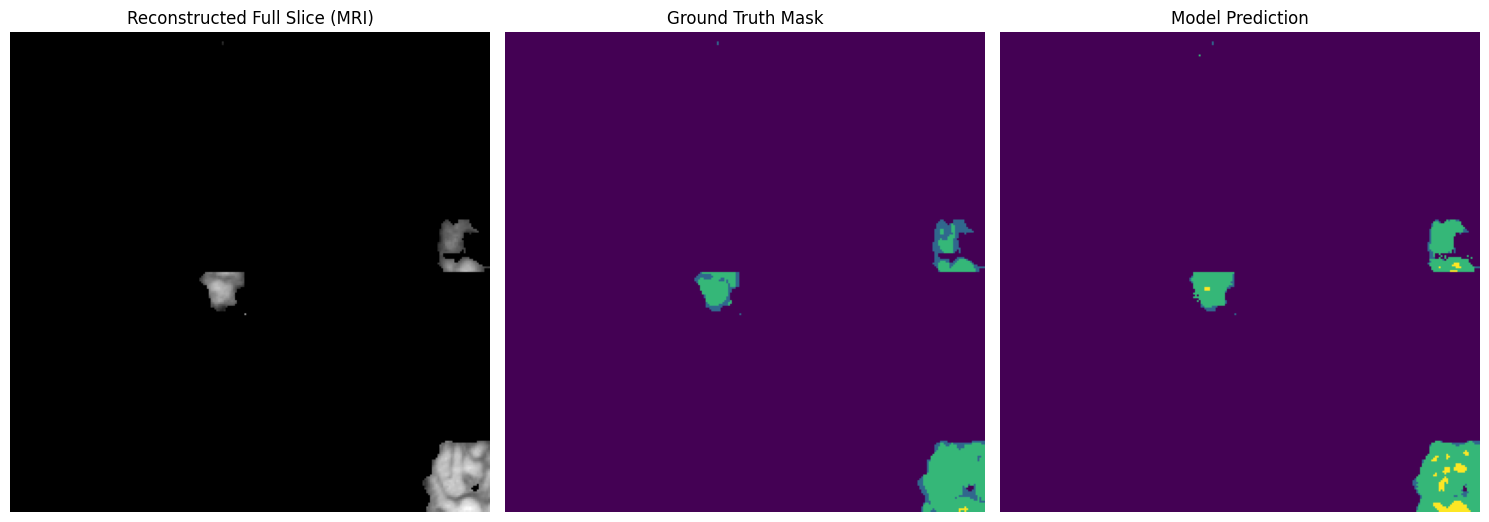


Plotting Training History...


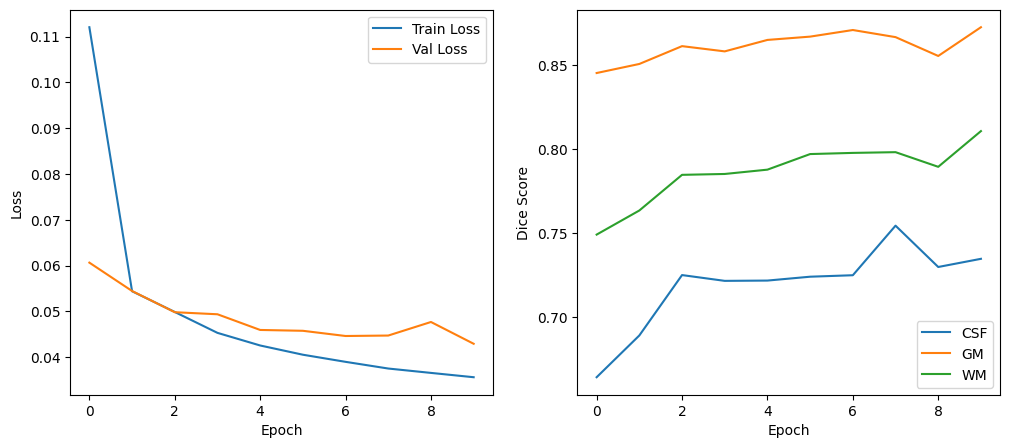

In [8]:
import matplotlib.pyplot as plt
import torch
import numpy as np

def visualize_full_slice(model, dataloader, device):
    model.eval()

    # 4 cosequtive batches,dataloader"shuffle" is off
    # batch order in dataset (0,0), (0,128), (128,0), (128,128)
    patches_img = []
    patches_mask = []
    patches_pred = []

    iterator = iter(dataloader)

    try:
        # grab 4 batches size 1
        for _ in range(4):
            img, mask = next(iterator)
            img = img.to(device)

            with torch.no_grad():
                output = model(img)
                pred = torch.argmax(output, dim=1)

            patches_img.append(img.cpu().squeeze().numpy())
            patches_mask.append(mask.cpu().squeeze().numpy())
            patches_pred.append(pred.cpu().squeeze().numpy())

    except StopIteration:
        print("Not enough patches to form a full slice!")
        return

    # Stitching
    # bottom row, p0,p1
    top_row_img = np.concatenate((patches_img[0], patches_img[1]), axis=1)
    top_row_mask = np.concatenate((patches_mask[0], patches_mask[1]), axis=1)
    top_row_pred = np.concatenate((patches_pred[0], patches_pred[1]), axis=1)

    # bottom row, p3,p2
    bot_row_img = np.concatenate((patches_img[2], patches_img[3]), axis=1)
    bot_row_mask = np.concatenate((patches_mask[2], patches_mask[3]), axis=1)
    bot_row_pred = np.concatenate((patches_pred[2], patches_pred[3]), axis=1)

    # whole
    full_img = np.concatenate((top_row_img, bot_row_img), axis=0)
    full_mask = np.concatenate((top_row_mask, bot_row_mask), axis=0)
    full_pred = np.concatenate((top_row_pred, bot_row_pred), axis=0)

    # show
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))

    axes[0].imshow(full_img, cmap='gray')
    axes[0].set_title("Reconstructed Full Slice (MRI)")
    axes[0].axis('off')

    axes[1].imshow(full_mask, cmap='viridis', vmin=0, vmax=3)
    axes[1].set_title("Ground Truth Mask")
    axes[1].axis('off')

    axes[2].imshow(full_pred, cmap='viridis', vmin=0, vmax=3)
    axes[2].set_title("Model Prediction")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

#Plot History Function
def plot_history(history):
    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Plot Dice Scores
    plt.subplot(1, 2, 2)
    plt.plot(history['val_dice_csf'], label='CSF')
    plt.plot(history['val_dice_gm'], label='GM')
    plt.plot(history['val_dice_wm'], label='WM')
    plt.xlabel('Epoch')
    plt.ylabel('Dice Score')
    plt.legend()

    plt.show()

# run
print("Visualizing Reconstructed Full Slice...")
visualize_full_slice(model, val_loader, device)

print("\nPlotting Training History...")
plot_history(history)


Visualizing Patient: IBSR_01_ana_strip.nii.gz


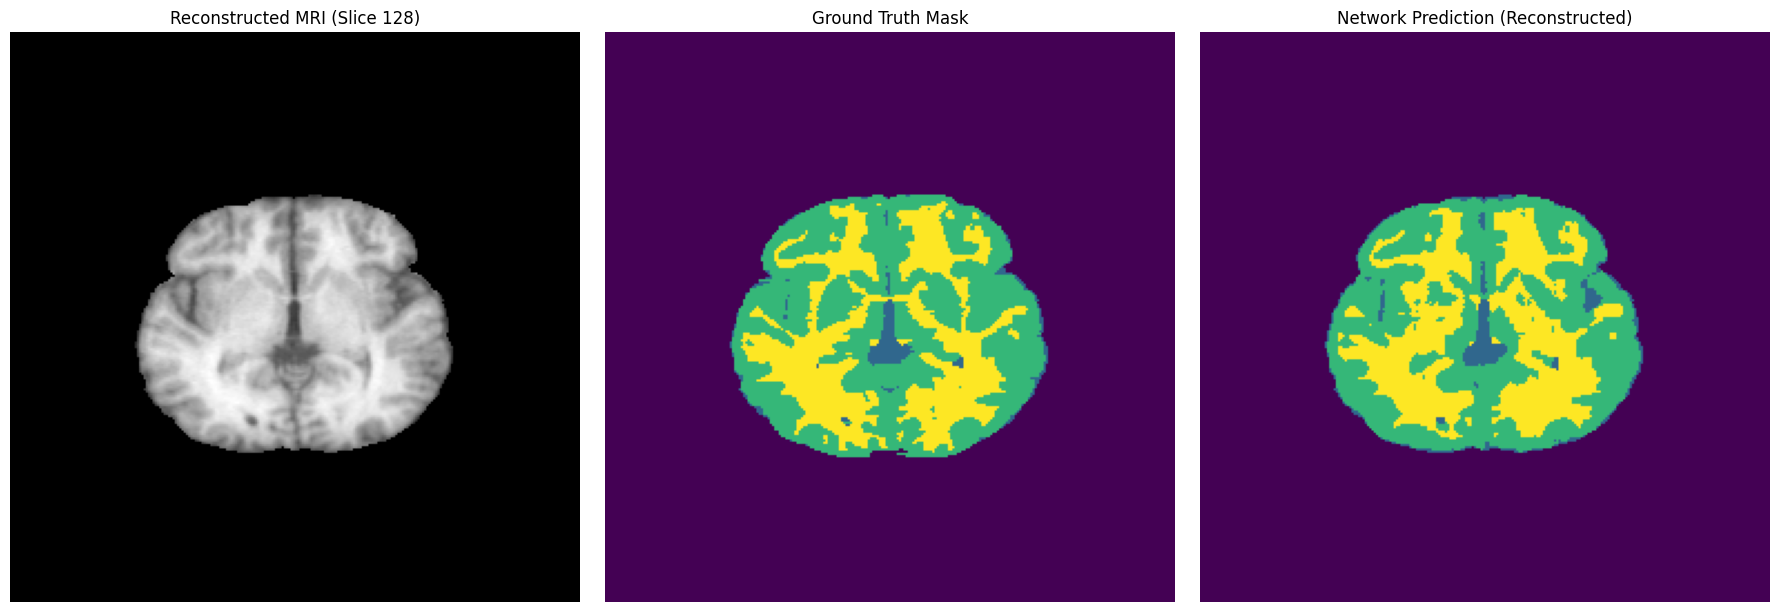

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import nibabel as nib
import os

def visualize_reconstructed_slice(model, vol_path, seg_path, slice_idx=None, axis=2):
    """
    This function takes a full slice, splits it into 4 patches, predicts, and stitches it back together.
    """
    model.eval()

    # 1. Load 3D volume
    vol_img = nib.load(vol_path).get_fdata().astype(np.float32)
    seg_img = nib.load(seg_path).get_fdata().astype(np.int64)

    # Normalization (similar to training)
    if vol_img.max() > 0:
        vol_img /= vol_img.max()

    # Select middle slice if not specified
    if slice_idx is None:
        slice_idx = vol_img.shape[axis] // 2

    # 2. Extract slice
    if axis == 0:
        img_slice = vol_img[slice_idx, :, :]
        mask_slice = seg_img[slice_idx, :, :]
    elif axis == 1:
        img_slice = vol_img[:, slice_idx, :]
        mask_slice = seg_img[:, slice_idx, :]
    else: # axis == 2 (Axial)
        img_slice = vol_img[:, :, slice_idx]
        mask_slice = seg_img[:, :, slice_idx]

    # Rotate for correct display
    img_slice = np.rot90(np.squeeze(img_slice), k=1)
    mask_slice = np.rot90(np.squeeze(mask_slice), k=1)

    # 3. Pad to 256x256 (to be able to split into 4 patches of 128)
    h, w = img_slice.shape
    pad_h = (256 - h) // 2
    pad_w = (256 - w) // 2
    img_padded = np.pad(img_slice, ((pad_h, 256-h-pad_h), (pad_w, 256-w-pad_w)), 'constant')
    mask_padded = np.pad(mask_slice, ((pad_h, 256-h-pad_h), (pad_w, 256-w-pad_w)), 'constant')

    # 4. Split into 4 patches and predict
    # Patch coordinates: (Top-Left), (Top-Right), (Bottom-Left), (Bottom-Right)
    coords = [(0, 0), (0, 128), (128, 0), (128, 128)]
    full_pred = np.zeros_like(mask_padded)

    for r, c in coords:
        # Extract patch
        patch_img = img_padded[r:r+128, c:c+128]

        # Convert to tensor
        patch_tensor = torch.tensor(patch_img, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

        # Model prediction
        with torch.no_grad():
            output = model(patch_tensor)
            pred_patch = torch.argmax(output, dim=1).squeeze().cpu().numpy()

        # Place into full image
        full_pred[r:r+128, c:c+128] = pred_patch

    # 5. Display results
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Original Image (MRI)
    axes[0].imshow(img_padded, cmap='gray')
    axes[0].set_title(f"Reconstructed MRI (Slice {slice_idx})")
    axes[0].axis('off')

    # Ground Truth Mask
    axes[1].imshow(mask_padded, cmap='viridis', vmin=0, vmax=3)
    axes[1].set_title("Ground Truth Mask")
    axes[1].axis('off')

    # Network Prediction
    axes[2].imshow(full_pred, cmap='viridis', vmin=0, vmax=3)
    axes[2].set_title("Network Prediction (Reconstructed)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

#Run function for a random patient
# Using validation file list (val_vol) separated previously
if 'val_vol' in globals() and len(val_vol) > 0:
    sample_idx = 0 # First test patient
    print(f"Visualizing Patient: {os.path.basename(val_vol[sample_idx])}")

    # Display middle axial slice
    visualize_reconstructed_slice(model, val_vol[sample_idx], val_seg[sample_idx], axis=2)
else:
    print("Validation data not found. Please run the data splitting cell first.")
